# 02 — Feature Importance Analysis

Sections: LightGBM importance, SHAP values, correlation heatmap, PSI drift.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings; warnings.filterwarnings('ignore')
sns.set_theme(style='darkgrid')
print('Ready.')

Ready.


In [2]:
import os
import json

# Load extracted features from data/processed
data_dir = os.path.abspath(os.path.join('..', 'data', 'processed'))
X = np.load(os.path.join(data_dir, 'X_180d.npy'))
close_prices = np.load(os.path.join(data_dir, 'close_180d.npy'))

with open(os.path.join(data_dir, 'feature_names.json'), 'r') as f:
    feature_names = json.load(f)

# Compute future looking labels (1 if UP, 0 if DOWN)
horizon = 5
y = np.full(len(close_prices), np.nan, dtype=np.float64)
for i in range(len(close_prices) - horizon):
    y[i] = 1.0 if close_prices[i + horizon] > close_prices[i] else 0.0

valid_idx = ~np.isnan(y)
X = X[valid_idx]
y = y[valid_idx].astype(int)

print(f'X: {X.shape}, label rate: {y.mean():.3f}')


X: (51635, 152), label rate: 0.502


Val log-loss: 0.7091 | AUC: 0.5344


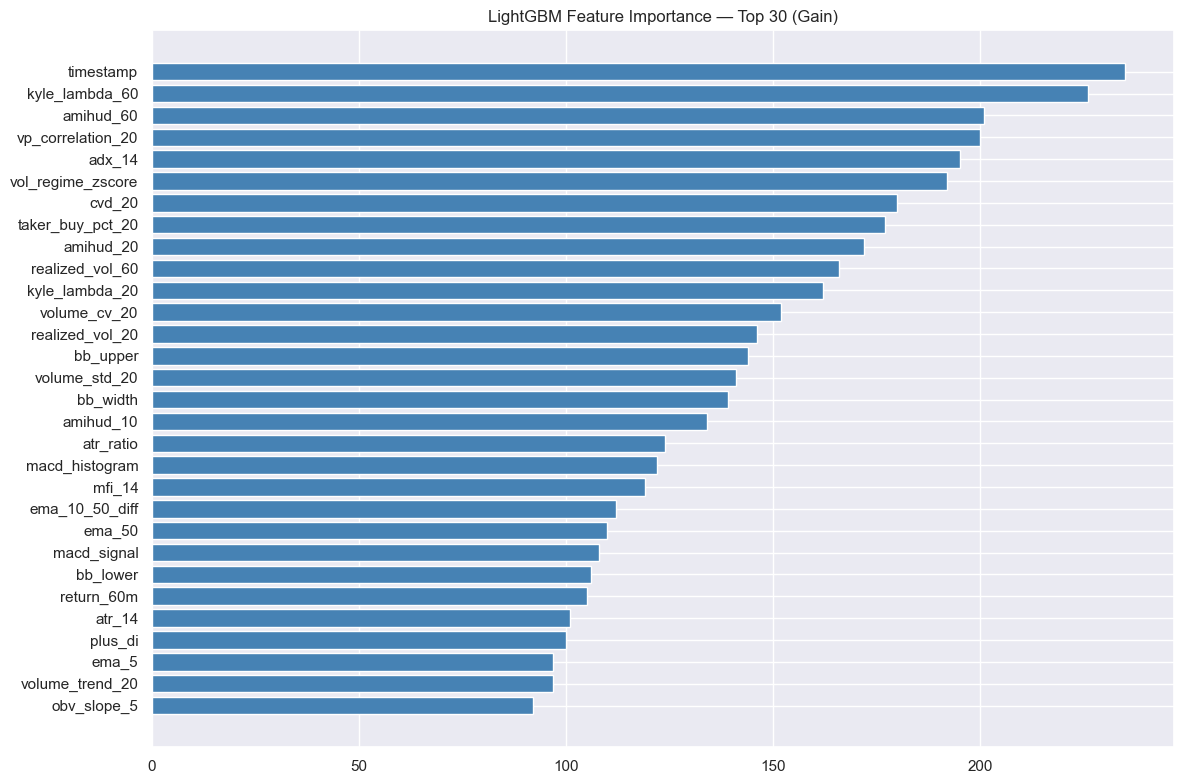

In [3]:
# LightGBM importance
try:
    import lightgbm as lgb
    from sklearn.model_selection import TimeSeriesSplit
    from sklearn.metrics import log_loss, roc_auc_score
    train_idx, val_idx = list(TimeSeriesSplit(3).split(X))[-1]
    model = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.05, max_depth=5,
                                 random_state=42, n_jobs=-1, verbose=-1)
    model.fit(X[train_idx], y[train_idx])
    val_proba = model.predict_proba(X[val_idx])[:,1]
    print(f'Val log-loss: {log_loss(y[val_idx], val_proba):.4f} | AUC: {roc_auc_score(y[val_idx], val_proba):.4f}')
    importance_df = pd.DataFrame({'feature': feature_names, 'gain': model.feature_importances_}).sort_values('gain', ascending=False)
    top30 = importance_df.head(30)
    fig, ax = plt.subplots(figsize=(12, 8))
    ax.barh(top30['feature'][::-1], top30['gain'][::-1], color='steelblue')
    ax.set_title('LightGBM Feature Importance — Top 30 (Gain)')
    plt.tight_layout(); plt.savefig('02_lgbm_importance.png', dpi=120); plt.show()
except ImportError:
    print('pip install lightgbm scikit-learn')

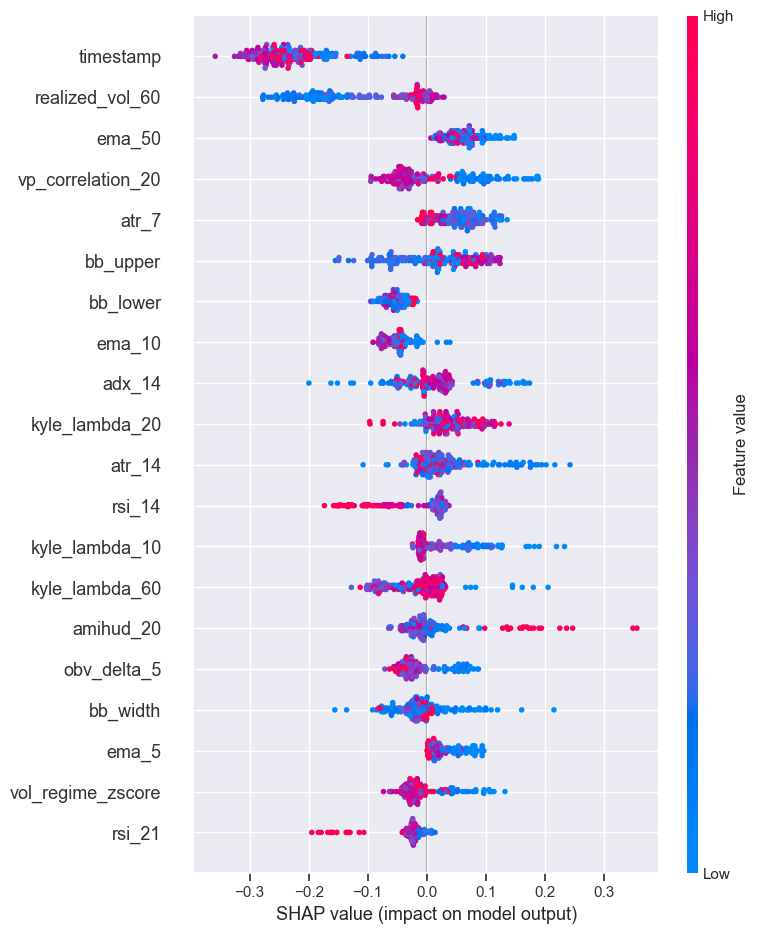

In [4]:
# SHAP values
try:
    import shap
    explainer = shap.TreeExplainer(model)
    shap_vals = explainer.shap_values(X[val_idx[:200]])
    plt.figure(figsize=(12, 8))
    shap.summary_plot(shap_vals[1] if isinstance(shap_vals, list) else shap_vals,
                      X[val_idx[:200]], feature_names=feature_names, max_display=20, show=False)
    plt.tight_layout(); plt.savefig('02_shap_summary.png', dpi=120); plt.show()
except ImportError:
    print('pip install shap')

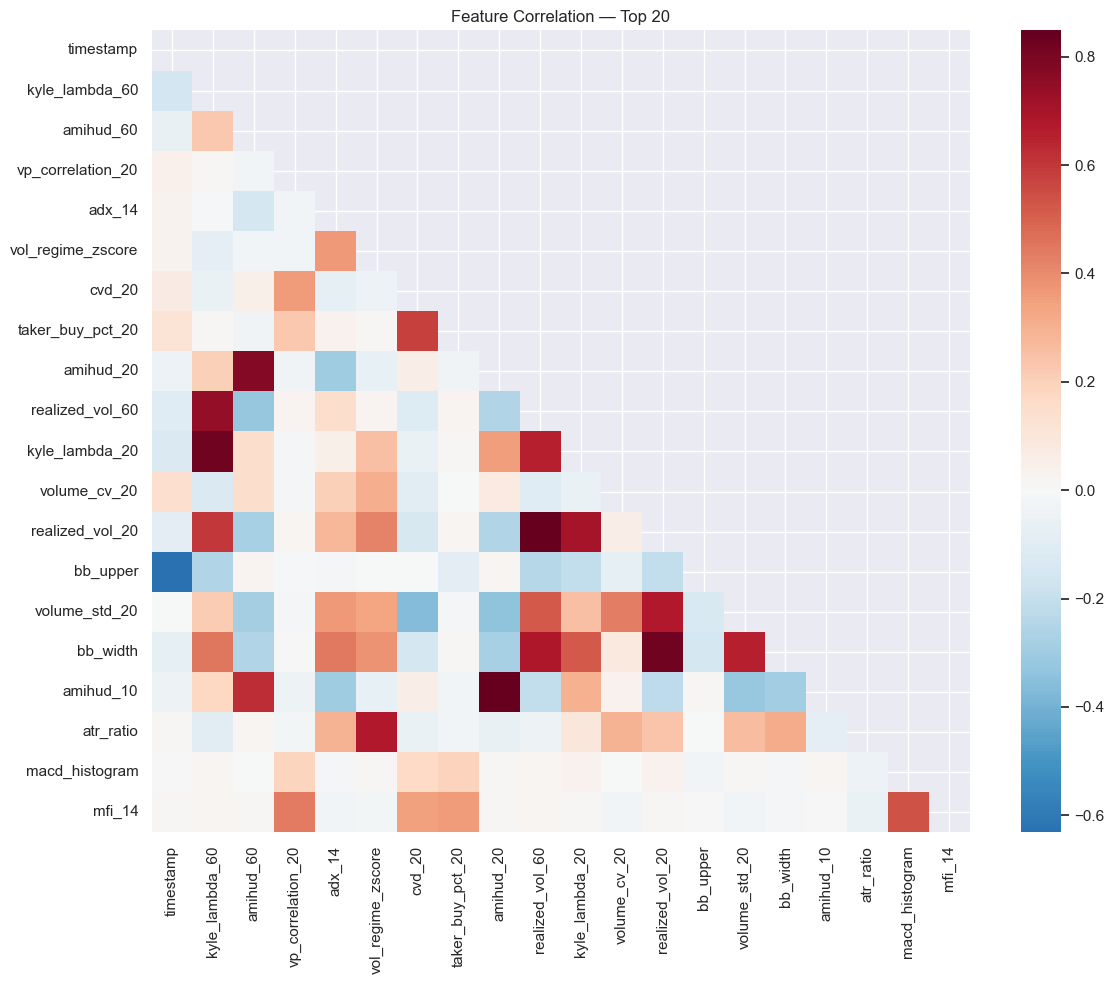

In [5]:
# Correlation heatmap — top 20 by importance
top20 = importance_df.head(20)['feature'].tolist()
top20_idx = [feature_names.index(n) for n in top20]
corr = pd.DataFrame(X[:, top20_idx], columns=top20).corr()
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool)),
            annot=False, cmap='RdBu_r', center=0, ax=ax)
ax.set_title('Feature Correlation — Top 20')
plt.tight_layout(); plt.savefig('02_correlation.png', dpi=120); plt.show()

In [6]:
# PSI — Population Stability Index
def compute_psi(expected, actual, buckets=10):
    bins = np.percentile(expected, np.linspace(0, 100, buckets+1))
    bins[0] -= 1e-10; bins[-1] += 1e-10
    ep = np.histogram(expected, bins=bins)[0] / len(expected) + 1e-8
    ap = np.histogram(actual, bins=bins)[0] / len(actual) + 1e-8
    return float(np.sum((ap - ep) * np.log(ap / ep)))

mid = len(X) // 2
psi_scores = [(feature_names[i], round(compute_psi(X[:mid,i], X[mid:,i]), 4)) for i in top20_idx]
psi_df = pd.DataFrame(psi_scores, columns=['feature','psi']).sort_values('psi', ascending=False)
print('PSI scores (drift: <0.1 stable, 0.1-0.25 slight, >0.25 significant):')
print(psi_df.to_string(index=False))

PSI scores (drift: <0.1 stable, 0.1-0.25 slight, >0.25 significant):
          feature     psi
        timestamp 16.1181
         bb_upper 14.2178
     volume_cv_20  0.1629
    volume_std_20  0.1597
   kyle_lambda_60  0.0838
  realized_vol_60  0.0714
 taker_buy_pct_20  0.0682
           cvd_20  0.0533
  realized_vol_20  0.0485
   kyle_lambda_20  0.0479
         bb_width  0.0400
   macd_histogram  0.0371
        amihud_60  0.0132
        atr_ratio  0.0131
        amihud_20  0.0109
           mfi_14  0.0098
vp_correlation_20  0.0097
vol_regime_zscore  0.0094
           adx_14  0.0083
        amihud_10  0.0064
